In [1]:
pip install pandas numpy scikit-learn matplotlib seaborn shap

  Using cached numpy-2.5.2-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached scikit_learn-1.9.0-cp314-cp314-win_amd64.whl.metadata (11 kB)
  Using cached matplotlib-3.11.1-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached shap-0.52.0-cp312-abi3-win_amd64.whl.metadata (26 kB)
  Using cached tzdata-2026.3-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
  Using cached contourpy-1.3.3-cp314-cp314-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pillow-12.3.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
  Using cached tqdm-4.70.0-py3-none-any.whl.metadata (57 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ------- ----------------

In [2]:
import pandas as pd

cols = ['checking_acct','duration','credit_history','purpose','credit_amount',
        'savings','employment','installment_rate','personal_status','other_debtors',
        'residence_since','property','age','other_installment','housing',
        'existing_credits','job','num_dependents','telephone','foreign_worker','target']

df = pd.read_csv('data/german.data', sep=' ', header=None, names=cols)
df.shape

(1000, 21)

In [3]:
df

,checking_acct,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installment,housing,existing_credits,job,num_dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,A14,12,A32,A42,1736,A61,A74,3,A92,A101,...,A121,31,A143,A152,1,A172,1,A191,A201,1
996,A11,30,A32,A41,3857,A61,A73,4,A91,A101,...,A122,40,A143,A152,1,A174,1,A192,A201,1
997,A14,12,A32,A43,804,A61,A75,4,A93,A101,...,A123,38,A143,A152,1,A173,1,A191,A201,1
998,A11,45,A32,A43,1845,A61,A73,4,A93,A101,...,A124,23,A143,A153,1,A173,1,A192,A201,2


In [4]:
df.head()

,checking_acct,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installment,housing,existing_credits,job,num_dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   checking_acct      1000 non-null   str  
 1   duration           1000 non-null   int64
 2   credit_history     1000 non-null   str  
 3   purpose            1000 non-null   str  
 4   credit_amount      1000 non-null   int64
 5   savings            1000 non-null   str  
 6   employment         1000 non-null   str  
 7   installment_rate   1000 non-null   int64
 8   personal_status    1000 non-null   str  
 9   other_debtors      1000 non-null   str  
 10  residence_since    1000 non-null   int64
 11  property           1000 non-null   str  
 12  age                1000 non-null   int64
 13  other_installment  1000 non-null   str  
 14  housing            1000 non-null   str  
 15  existing_credits   1000 non-null   int64
 16  job                1000 non-null   str  
 17  num_dependents     1000 no

In [6]:
df.isnull().sum().sum()

np.int64(0)

In [7]:
df['target'] = df['target'].map({1: 0, 2: 1})
df['target'].value_counts()

target
0    700
1    300
Name: count, dtype: int64

In [8]:
df['target'].value_counts(normalize=True)

target
0    0.7
1    0.3
Name: proportion, dtype: float64

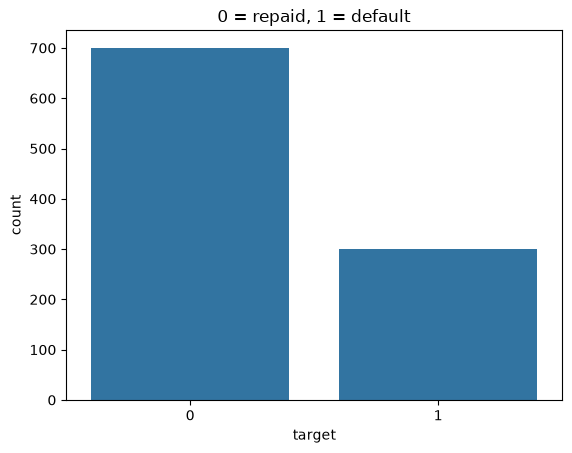

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='target', data=df)
plt.title('0 = repaid, 1 = default')
plt.show()

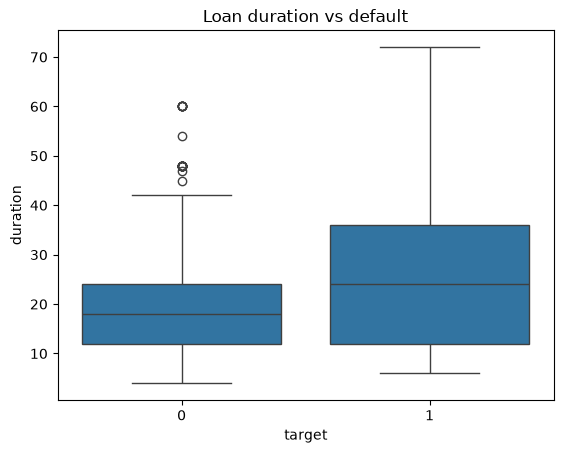

In [10]:
sns.boxplot(x='target', y='duration', data=df)
plt.title('Loan duration vs default')
plt.show()

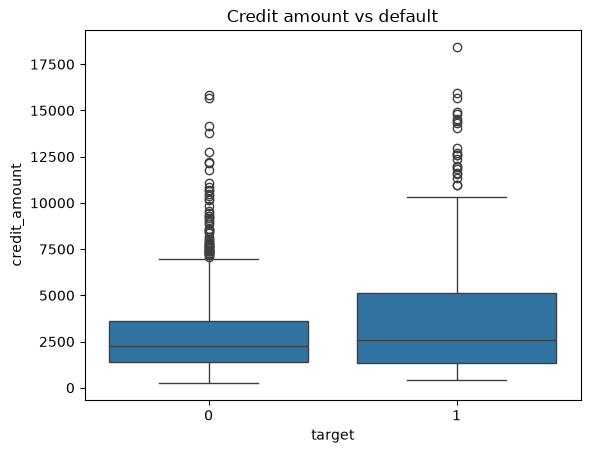

In [11]:
sns.boxplot(x='target', y='credit_amount', data=df)
plt.title('Credit amount vs default')
plt.show()

In [12]:
X = df.drop('target', axis=1)
y = df['target']
print(X.shape, y.shape)

(1000, 20) (1000,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

(800, 20) (200, 20)


In [14]:
import numpy as np

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print(f"Numeric ({len(num_cols)}):", num_cols)
print(f"Categorical ({len(cat_cols)}):", cat_cols)

Numeric (7): ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Categorical (13): ['checking_acct', 'credit_history', 'purpose', 'savings', 'employment', 'personal_status', 'other_debtors', 'property', 'other_installment', 'housing', 'job', 'telephone', 'foreign_worker']


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

In [17]:
baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['checking_acct','duration','credit_history',...,'num_dependents', 'telephone','foreign_worker']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

In [18]:
from sklearn.metrics import classification_report

y_pred = baseline.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.89      0.85       140
           1       0.67      0.53      0.59        60

    accuracy                           0.78       200
   macro avg       0.74      0.71      0.72       200
weighted avg       0.77      0.78      0.77       200



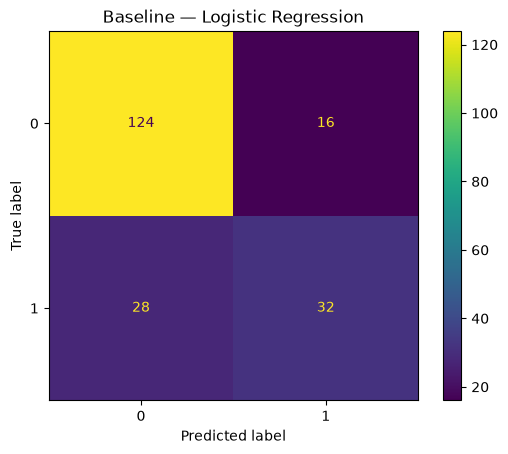

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title('Baseline — Logistic Regression')
plt.show()

In [20]:
from sklearn.metrics import roc_auc_score

proba = baseline.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))

ROC-AUC: 0.804


# ANOTHER WAY

In [21]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

rf = Pipeline([('prep', preprocessor),
               ('model', RandomForestClassifier(n_estimators=200, random_state=42))])
rf.fit(X_train, y_train)
print(classification_report(y_test, rf.predict(X_test)))

              precision    recall  f1-score   support

           0       0.78      0.91      0.84       140
           1       0.66      0.42      0.51        60

    accuracy                           0.76       200
   macro avg       0.72      0.66      0.68       200
weighted avg       0.75      0.76      0.74       200



In [22]:
gb = Pipeline([('prep', preprocessor),
               ('model', GradientBoostingClassifier(random_state=42))])
gb.fit(X_train, y_train)
print(classification_report(y_test, gb.predict(X_test)))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86       140
           1       0.69      0.57      0.62        60

    accuracy                           0.80       200
   macro avg       0.76      0.73      0.74       200
weighted avg       0.79      0.80      0.79       200



In [23]:
from sklearn.metrics import average_precision_score

def evaluate(name, fitted_pipe):
    p = fitted_pipe.predict_proba(X_test)[:, 1]
    pred = fitted_pipe.predict(X_test)
    rec = classification_report(y_test, pred, output_dict=True)['1']['recall']
    return {'model': name,
            'ROC_AUC': round(roc_auc_score(y_test, p), 3),
            'PR_AUC':  round(average_precision_score(y_test, p), 3),
            'Recall_default': round(rec, 3)}

results = [evaluate('LogReg', baseline),
           evaluate('RandomForest', rf),
           evaluate('GradBoost', gb)]
pd.DataFrame(results)

,model,ROC_AUC,PR_AUC,Recall_default
0,LogReg,0.804,0.635,0.533
1,RandomForest,0.784,0.634,0.417
2,GradBoost,0.792,0.630,0.567


In [24]:
logreg_bal = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
logreg_bal.fit(X_train, y_train)
print(classification_report(y_test, logreg_bal.predict(X_test)))

              precision    recall  f1-score   support

           0       0.89      0.73      0.80       140
           1       0.56      0.80      0.66        60

    accuracy                           0.75       200
   macro avg       0.73      0.76      0.73       200
weighted avg       0.79      0.75      0.76       200



In [25]:
rf_bal = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42))
])
rf_bal.fit(X_train, y_train)

results += [evaluate('LogReg_balanced', logreg_bal),
            evaluate('RF_balanced', rf_bal)]
pd.DataFrame(results)

,model,ROC_AUC,PR_AUC,Recall_default
0,LogReg,0.804,0.635,0.533
1,RandomForest,0.784,0.634,0.417
2,GradBoost,0.792,0.630,0.567
3,LogReg_balanced,0.806,0.633,0.800
4,RF_balanced,0.801,0.628,0.600


In [26]:
from sklearn.model_selection import cross_val_score

cv = cross_val_score(logreg_bal, X, y, cv=5, scoring='roc_auc')
print(f"CV ROC-AUC: {cv.mean():.3f} (+/- {cv.std():.3f})")

CV ROC-AUC: 0.788 (+/- 0.016)


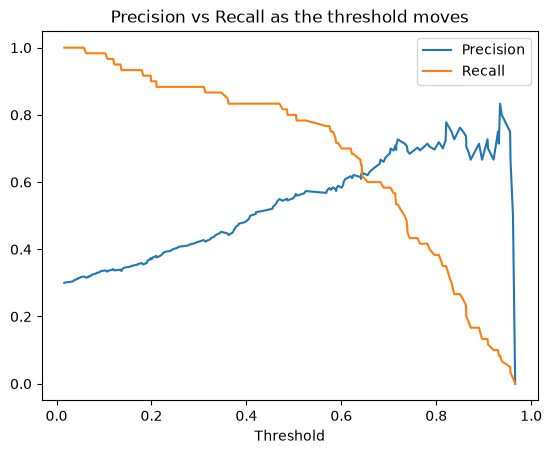

In [27]:
from sklearn.metrics import precision_recall_curve

proba = logreg_bal.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)

plt.plot(thr, prec[:-1], label='Precision')
plt.plot(thr, rec[:-1],  label='Recall')
plt.xlabel('Threshold'); plt.legend()
plt.title('Precision vs Recall as the threshold moves')
plt.show()

In [28]:
import numpy as np
from sklearn.metrics import confusion_matrix

COST_FN = 5   # missing a defaulter — we lose the loan
COST_FP = 1   # rejecting a good customer — we lose their margin

rows = []
for t in np.arange(0.1, 0.9, 0.02):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'threshold': t, 'cost': fp * COST_FP + fn * COST_FN})

costs = pd.DataFrame(rows)
best_t = costs.loc[costs['cost'].idxmin(), 'threshold']
print(f"Optimal threshold: {best_t:.2f}")

Optimal threshold: 0.46


              precision    recall  f1-score   support

           0       0.91      0.69      0.78       140
           1       0.53      0.83      0.65        60

    accuracy                           0.73       200
   macro avg       0.72      0.76      0.71       200
weighted avg       0.79      0.73      0.74       200



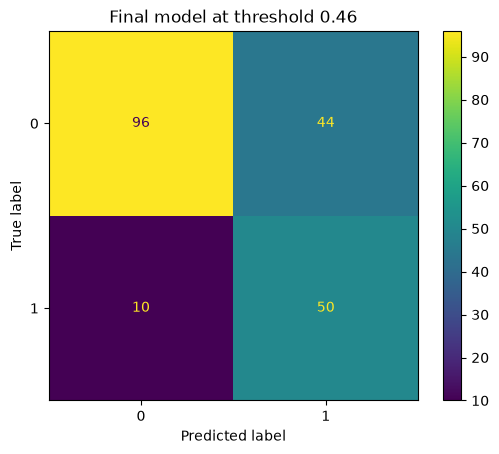

In [29]:
y_final = (proba >= best_t).astype(int)
print(classification_report(y_test, y_final))

ConfusionMatrixDisplay.from_predictions(y_test, y_final)
plt.title(f'Final model at threshold {best_t:.2f}')
plt.show()

# INTERPRETATION

In [30]:
rf_bal.fit(X_train, y_train)

feat_names = rf_bal.named_steps['prep'].get_feature_names_out()
importances = rf_bal.named_steps['model'].feature_importances_

imp = pd.DataFrame({'feature': feat_names, 'importance': importances}) \
        .sort_values('importance', ascending=False).head(10)
imp

,feature,importance
1,num__credit_amount,0.090901
0,num__duration,0.080942
4,num__age,0.069142
10,cat__checking_acct_A14,0.066259
7,cat__checking_acct_A11,0.034465
2,num__installment_rate,0.034108
3,num__residence_since,0.031675
15,cat__credit_history_A34,0.026223
26,cat__savings_A61,0.021390
8,cat__checking_acct_A12,0.020131


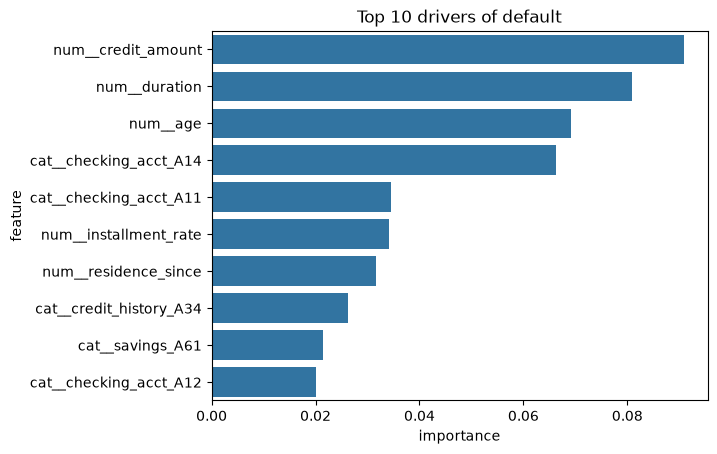

In [31]:
sns.barplot(x='importance', y='feature', data=imp)
plt.title('Top 10 drivers of default')
plt.show()

In [32]:
coefs = pd.DataFrame({
    'feature': logreg_bal.named_steps['prep'].get_feature_names_out(),
    'coef': logreg_bal.named_steps['model'].coef_[0]
}).sort_values('coef', ascending=False)

pd.concat([coefs.head(5), coefs.tail(5)])

,feature,coef
23,cat__purpose_A46,0.958526
46,cat__property_A124,0.635350
7,cat__checking_acct_A11,0.620797
11,cat__credit_history_A30,0.589948
26,cat__savings_A61,0.584578
60,cat__foreign_worker_A202,-0.651421
29,cat__savings_A64,-0.676792
15,cat__credit_history_A34,-0.852003
17,cat__purpose_A41,-0.887080
10,cat__checking_acct_A14,-0.987410


In [33]:
import joblib

joblib.dump(logreg_bal, 'credit_model.pkl')
print("Saved.")

Saved.


In [34]:
loaded = joblib.load('credit_model.pkl')

applicant = X_test.iloc[[0]]
p = loaded.predict_proba(applicant)[0, 1]

print(f"Default probability: {p:.1%}")
print(f"Decision at threshold {best_t:.2f}: {'REJECT' if p >= best_t else 'APPROVE'}")

Default probability: 40.7%
Decision at threshold 0.46: APPROVE


In [35]:
pd.DataFrame(results).sort_values('PR_AUC', ascending=False)

,model,ROC_AUC,PR_AUC,Recall_default
0,LogReg,0.804,0.635,0.533
1,RandomForest,0.784,0.634,0.417
3,LogReg_balanced,0.806,0.633,0.800
2,GradBoost,0.792,0.630,0.567
4,RF_balanced,0.801,0.628,0.600
